In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.base import clone

In [42]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


In [43]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isna().sum()

np.int64(11)

In [44]:
x=df.drop(columns=["customerID", "Churn"])
y=df["Churn"].map({"Yes": 1, "No": 0})


In [45]:
print(x.shape)
print(y.value_counts())

(7043, 19)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [46]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)

(5634, 19)
(1409, 19)


In [47]:
print(X_train["TotalCharges"].isna().sum())
print(X_test["TotalCharges"].isna().sum())

8
3


In [48]:
median_charges = X_train["TotalCharges"].median()

X_train["TotalCharges"] = X_train["TotalCharges"].fillna(median_charges)
X_test["TotalCharges"] = X_test["TotalCharges"].fillna(median_charges)

print("Train missing:", X_train["TotalCharges"].isna().sum())
print("Test missing:", X_test["TotalCharges"].isna().sum())

Train missing: 0
Test missing: 0


In [49]:
text_columns = X_train.select_dtypes(exclude="number").columns
text_columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), text_columns)
    ],
    remainder="passthrough"
)
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded train shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Encoded train shape: (5634, 45)
Encoded test shape: (1409, 45)


Baseline model

In [51]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_encoded, y_train)

baseline_pred = baseline.predict(X_test_encoded)

print(f"Accuracy: {accuracy_score(y_test, baseline_pred):.1%}")
print(f"Churn recall: {recall_score(y_test, baseline_pred):.1%}")
print(f"F1 score: {f1_score(y_test, baseline_pred):.1%}")

Accuracy: 73.5%
Churn recall: 0.0%
F1 score: 0.0%


logistic model


In [52]:
logistic_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(max_iter=1000)
)
logistic_model.fit(X_train_encoded, y_train)
logistic_pred = logistic_model.predict(X_test_encoded)

print(f"Accuracy: {accuracy_score(y_test, logistic_pred):.1%}")
print(f"Churn recall: {recall_score(y_test, logistic_pred):.1%}")
print(f"F1 score: {f1_score(y_test, logistic_pred):.1%}")

Accuracy: 80.7%
Churn recall: 56.7%
F1 score: 60.9%


Decision_tree model

In [53]:
tree_model = DecisionTreeClassifier(max_depth=10, random_state=42)
tree_model.fit(X_train_encoded, y_train)

tree_pred = tree_model.predict(X_test_encoded)

print(f"Accuracy: {accuracy_score(y_test, tree_pred):.1%}")
print(f"Churn recall: {recall_score(y_test, tree_pred):.1%}")
print(f"F1 score: {f1_score(y_test, tree_pred):.1%}")

Accuracy: 75.3%
Churn recall: 52.7%
F1 score: 53.1%


RandomForest

In [54]:

forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
forest_model.fit(X_train_encoded, y_train)

forest_pred = forest_model.predict(X_test_encoded)

print(f"Accuracy: {accuracy_score(y_test, forest_pred):.1%}")
print(f"Churn recall: {recall_score(y_test, forest_pred):.1%}")
print(f"F1 score: {f1_score(y_test, forest_pred):.1%}")

Accuracy: 78.1%
Churn recall: 48.4%
F1 score: 54.0%


In [55]:
models = {
    "Baseline": baseline,
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

results = []

for name, model in models.items():
    prediction = model.predict(X_test_encoded)
    churn_probability = model.predict_proba(X_test_encoded)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction),
        "F1": f1_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, churn_probability)
    })

comparison = pd.DataFrame(results).set_index("Model")
comparison = comparison.sort_values("F1", ascending=False)
display(comparison.style.format("{:.1%}"))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,80.7%,65.8%,56.7%,60.9%,84.2%
Random Forest,78.1%,61.1%,48.4%,54.0%,81.8%
Decision Tree,75.3%,53.5%,52.7%,53.1%,75.0%
Baseline,73.5%,0.0%,0.0%,0.0%,50.0%


Hyperparameter Tuning

![alt text]({89028C3D-F7D0-42C6-AC6C-09059BC4FFAE}.png)

In [56]:
X_train_raw = x.loc[X_train.index]

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), text_columns),
        ("charges", SimpleImputer(strategy="median"), ["TotalCharges"])
    ],
    remainder="passthrough"
)

tree_pipeline = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("tree", DecisionTreeClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid={"tree__max_depth": [3, 5, 7, 10, 15, None]},
    scoring="f1",
    cv=cv
)

search.fit(X_train_raw, y_train)

depth_results = pd.DataFrame({
    "Max depth": search.cv_results_["params"],
    "Mean validation F1": search.cv_results_["mean_test_score"]
})
depth_results["Max depth"] = [
    str(params["tree__max_depth"]) for params in depth_results["Max depth"]
]

display(
    depth_results.sort_values("Mean validation F1", ascending=False)
    .style.format({"Mean validation F1": "{:.1%}"})
)

best_tree = search.best_estimator_
print("Best max_depth:", search.best_params_["tree__max_depth"])

,Max depth,Mean validation F1
2,7,57.0%
1,5,56.5%
3,10,52.7%
4,15,49.9%
5,None,48.8%
0,3,47.8%


Best max_depth: 7


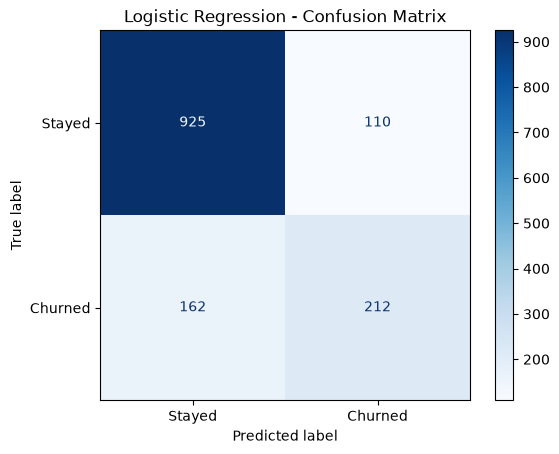

In [57]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    labels=[0, 1],
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [58]:
test_results = X_test[["Contract"]].copy()
test_results["Actual"] = y_test
test_results["Predicted"] = logistic_pred

# ناخد العملاء اللي سابوا الخدمة فعلًا
churned = test_results.loc[test_results["Actual"] == 1].copy()

# العميل فات الموديل لو الموديل توقّع إنه هيكمل
churned["Missed"] = churned["Predicted"] == 0

error_summary = churned.groupby("Contract").agg(
    actual_churners=("Missed", "size"),
    missed_churners=("Missed", "sum")
)

error_summary["miss_rate"] = (
    error_summary["missed_churners"] / error_summary["actual_churners"]
)

display(error_summary.style.format({"miss_rate": "{:.1%}"}))

,actual_churners,missed_churners,miss_rate
Contract,,,
Month-to-month,329,117,35.6%
One year,36,36,100.0%
Two year,9,9,100.0%


final pipline

In [59]:
X_train_raw = x.loc[X_train.index]
X_test_raw = x.loc[X_test.index]

final_pipeline = make_pipeline(
    clone(tree_preprocessor),
    StandardScaler(with_mean=False),
    LogisticRegression(max_iter=1000)
)

final_pipeline.fit(X_train_raw, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories', ...), ('charges', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [60]:
final_pred = final_pipeline.predict(X_test_raw)
print(f"Final Accuracy: {accuracy_score(y_test, final_pred):.1%}")
print(f"Final Churn recall: {recall_score(y_test, final_pred):.1%}")
print(f"Final F1: {f1_score(y_test, final_pred):.1%}")

Final Accuracy: 80.7%
Final Churn recall: 56.7%
Final F1: 60.9%


In [61]:
import joblib

joblib.dump(final_pipeline, "../models/churn_pipeline.joblib")

['../models/churn_pipeline.joblib']